In [178]:
from __future__ import annotations

import time
from dataclasses import dataclass
from time import perf_counter

import numpy as np
import pandas as pd
from scipy.special import expit
from collections import deque
import matplotlib.pyplot as plt
from copy import deepcopy
from time import perf_counter

from typing import List, Dict, Tuple, Optional

# Online Causal Forest

The Online Causal Forest training algorithm is the following:

1. We receive a new datapoint $W_i = (Y_i, D_i, X_i)$
2. The Forest consumes this point and updates summaries and/or splits leafs

## How Forest looks like
The forest consists of $B$ trees $T_b$. Each datapoint is passed to every tree in a forest. The CATE $\tau(x)$ is an average of computed CATEs of each forest:
$$ \tau(x) = \frac{1}{B}\sum_{b=1}^B \tau_b(x). $$

## How each tree splits

Each tree pushes a new observation down to a leaf according to the splits the tree have already made. Every observation becomes either a part of an estimation stream or a structural stream. If its a part of estimation stream, then this observation is used for computation of ATE, otherwise it is used to determine the next split.

Whenever a new leaf is created, we draw a number $m = max(Poisson(\theta) + 1, max_features)$, and then take random $m$ features ${i}$ at which candidate splits will be considered. Then, we create a grid ${c_j}_{j=1}^J$ of a support of each chosen feature. For each pair (i, c) we keep track of summaries $(n_0, n_1, Y_0, Y_1)$, where $n_d$ is a number of observations in a group $d$ and $Y_d$ is a sum of outcomes in a group $d$. In order to determine a split, we wait until the leaf observes at least $n_{struct}$ structural observations and then we split at the $(i, c)$ which yields the maximum heterogeneity between two groups:
$$ (i, c)^* = \text{argmax}_{s = (i, c)} w_L(s)w_R(s)(\tau_L(s) - \tau_R(s))^2, $$
where $w_L(s) = \frac{n_L(s)}{n(s)}$, $n_L(s)$ is the number of observations in a left child, $n_(s)$ is a total number of observations, and $\tau_L(s)$ is an ATE of the left child.

Each leaf's ATE is computed simply as:
$$ \tau(x) = ATE_{current},   $$
where the ATE is using observations from when the split was being decided (from estimation stream) plus the observations that end up in a leaf.

In [255]:
@dataclass
class DataPoint:
    y: float
    d: int
    x: np.ndarray


def dgp0_cate(x: np.ndarray) -> float:
    return float(x.mean())

def dgp1_cate(x: np.ndarray) -> float:
    return float(np.abs(np.sin(x.mean() - 1/2)) + np.cos(x.std()))

def dgp2_cate(x: np.ndarray) -> float:
    return float(np.abs(1 - np.cos(x.mean() - 1/2)) + np.sin(x.std()))

def prop1_cate(x: np.ndarray, beta: float = 8.0) -> float:
    return expit(beta * (x.mean() - 1/2))

def prop0_cate(x: np.ndarray) -> float:
    return 1/2

class RandomDataStream:
    def __init__(
            self,
            n_features: int,
            sigma: float = 1,
            treatment_p: float = 0.5,
            bounds: list[tuple[float, float]] | None = None,
            seed: int = 123,
    ) -> None:
        self.n_features = n_features
        self.seed = seed
        self.rng = np.random.default_rng(seed=self.seed)
        self.sigma = sigma
        self.treatment_p = treatment_p

        if bounds is None:
            self.bounds = [(0.0, 1.0) for _ in range(n_features)]
        else:
            self.bounds = bounds

    def generate_new_data(self, mu1, mu0, prop) -> DataPoint:
        x = self.rng.uniform(0, 1, size=self.n_features)
        eps = self.rng.normal(loc=0.0, scale=self.sigma)

        propensity = prop(x)

        d = int(self.rng.binomial(n=1, p=propensity))

        y = mu0(x) + d * mu1(x) + eps

        return DataPoint(y=y, d=d, x=x)


In [256]:
class CandidateSummaries:
    def __init__(self, features: np.ndarray, thresholds: np.ndarray) -> None:
        self.features = features
        self.thresholds = thresholds
        self.n_cand = len(self.features)

        shape = (self.n_cand, 2)

        self.n0 = np.zeros(shape, dtype=np.int32)
        self.n1 = np.zeros(shape, dtype=np.int32)
        self.y0 = np.zeros(shape, dtype=np.float64)
        self.y1 = np.zeros(shape, dtype=np.float64)

        self.candidate_idx = np.arange(self.n_cand)

    def update(self, x: np.ndarray, d: int, y: float) -> None:
        sides = (x[self.features] >= self.thresholds).astype(np.int8)

        if d == 1:
            self.n1[self.candidate_idx, sides] += 1
            self.y1[self.candidate_idx, sides] += y
        else:
            self.n0[self.candidate_idx, sides] += 1
            self.y0[self.candidate_idx, sides] += y

    def valid_mask(self, min_arm: int = 1) -> np.ndarray:
        return (
            (self.n0[:, 0] >= min_arm)
            & (self.n1[:, 0] >= min_arm)
            & (self.n0[:, 1] >= min_arm)
            & (self.n1[:, 1] >= min_arm)
        )

    def tau(self) -> np.ndarray:
        tau = np.empty((self.n_cand, 2), dtype=np.float64)

        with np.errstate(divide="ignore", invalid="ignore"):
            tau[:, 0] = self.y1[:, 0] / self.n1[:, 0] - self.y0[:, 0] / self.n0[:, 0]
            tau[:, 1] = self.y1[:, 1] / self.n1[:, 1] - self.y0[:, 1] / self.n0[:, 1]

        return tau

    def split_scores(self, min_arm: int = 1) -> np.ndarray:
        valid = self.valid_mask(min_arm=min_arm)
        tau = self.tau()

        n_left = self.n0[:, 0] + self.n1[:, 0]
        n_right = self.n0[:, 1] + self.n1[:, 1]
        n_total = n_left + n_right

        with np.errstate(divide="ignore", invalid="ignore"):
            w_left = n_left / n_total
            w_right = n_right / n_total
            score = w_left * w_right * (tau[:, 0] - tau[:, 1]) ** 2

        score[~valid] = -np.inf
        return score

    def best_split_index(self, min_arm: int = 1) -> int | None:
        scores = self.split_scores(min_arm=min_arm)

        if np.all(np.isneginf(scores)):
            return None

        return int(np.argmax(scores))

@dataclass(frozen=True)
class SplitLocation:
    feature: int
    threshold: float

    def is_data_point_to_right(self, x: np.ndarray) -> bool:
        return x[self.feature] >= self.threshold


@dataclass(slots=True)
class OnlineSummaries:
    n_0: int = 0
    n_1: int = 0
    y_0: float = 0.0
    y_1: float = 0.0

    def update(self, d: int, y: float) -> None:
        if d == 1:
            self.n_1 += 1
            self.y_1 += y
        else:
            self.n_0 += 1
            self.y_0 += y

    def is_invalid(self, min_arm: int = 1) -> bool:
        return self.n_0 < min_arm or self.n_1 < min_arm

    def get_ate(self) -> float:
        if self.is_invalid():
            raise ValueError("Invalid ATE: missing treatment arm.")
        return self.y_1 / self.n_1 - self.y_0 / self.n_0


class CausalForest:
    def __init__(
            self,
            n_trees: int,
            theta: float,
            max_feature_split_subset_m: int,
            candidate_grid_size: int,
            c_estim: float,
            alpha_estim: float,
            c_split: float,
            alpha_split: float,
            growth_decay_factor: float,
            share_of_trees_to_mature: float,
            min_arm: int,
            height_threshold: int,
            ghost_branch_size: int,
            random_seed: int = 123,
    ) -> None:
        self.generations: List[List[CausalTree]] = []
        self.generations_age: List[int] = []
        self.share_of_matured_trees: List[float] = []
        self.n_trees: int = n_trees
        self.theta: float = theta
        self.max_feature_split_subset_m: int = max_feature_split_subset_m
        self.candidate_grid_size: int = candidate_grid_size
        self.c_split: float = c_split
        self.alpha_split: float = alpha_split
        self.alpha_estim: float = alpha_estim
        self.c_estim: float = c_estim
        self.growth_decay_factor: float = growth_decay_factor
        self.share_of_trees_to_mature: float = share_of_trees_to_mature
        self.min_arm: int = min_arm
        self.height_threshold: int = height_threshold
        self.ghost_branch_size: int = ghost_branch_size
        self.seed = random_seed
        self.stream: Optional[RandomDataStream] = None

        self.rng = np.random.default_rng(seed=self.seed)

        self._create_new_generation: bool = False

        self.active_trees: int = 0

    def create_new_generation(self) -> None:
        trees = []
        gen_id = len(self.generations)

        for b in range(self.n_trees):
            trees.append(
                CausalTree(
                    forest=self,
                    gen_id=gen_id,
                    random_seed=int(self.rng.integers(0, 2**32 - 1)),
                ).fit(self.stream)
            )

        self.generations.append(trees)
        self.generations_age.append(0)
        self.share_of_matured_trees.append(0.0)

    def fit(self, stream: RandomDataStream) -> 'CausalForest':
        self.stream = stream
        self.generations = []
        self.generations_age = []
        self.share_of_matured_trees = []
        self._create_new_generation = False
        self.create_new_generation()
        self.active_trees = self.n_trees

        return self

    def consume(self, x: np.ndarray, y: float, d: int) -> None:
        if self.stream is None:
            raise ValueError('Causal Forest has not been fit')

        for gen in self.generations:
            for tree in gen:
                tree.consume(y=y, d=d, x=x)

        if self._create_new_generation:
            self.create_new_generation()
            self._create_new_generation = False

    def compute_ate(self, x: np.ndarray) -> float:
        if self.stream is None:
            raise ValueError('Causal Forest has not been fit')

        num = 0.0
        den = 0.0

        for age, gen in enumerate(reversed(self.generations)):
            w = 1.0

            for tree in gen:
                if (not tree.tree_is_ready) or ((age < len(self.generations) - 1) and tree.height < self.height_threshold):
                    continue

                try:
                    pred = tree.compute_ate(x)
                except ValueError:
                    continue

                num += w * pred
                den += w

        if den == 0:
            raise ValueError("No valid tree prediction yet.")
        return num / den

    def generation_is_mature(self, gen_id: int) -> bool:
        return self.share_of_matured_trees[gen_id] >= self.share_of_trees_to_mature

    def update_height(self, new_height: int, gen_id: int) -> None:
        if new_height % self.height_threshold == 0:
            if gen_id > 0 and new_height // self.height_threshold == 1:
                self.active_trees += 1

            self.share_of_matured_trees[gen_id] += 1 / self.n_trees

        if self.generation_is_mature(gen_id):
            self.generations_age[gen_id] += 1

            if self.generations_age[gen_id] == 1:
                self._create_new_generation = True

            self.share_of_matured_trees[gen_id] = 0


class CausalTree:
    def __init__(
            self,
            forest: CausalForest,
            gen_id: int,
            random_seed: int = 123,
    ) -> None:
        self.root: Optional[TreeNode] = None
        self.height: int = 0
        self.num_leaves: int = 0
        self.stream: Optional[RandomDataStream] = None
        self.forest = forest
        self.gen_id = gen_id

        self.theta: float = forest.theta
        self.max_feature_split_subset_m: int = forest.max_feature_split_subset_m
        self.min_arm: int = forest.min_arm
        self.candidate_grid_size: int = forest.candidate_grid_size
        self.c_split: float = forest.c_split
        self.alpha_split: float = forest.alpha_split
        self.c_estim: float = forest.c_estim
        self.alpha_estim: float = forest.alpha_estim
        self.ghost_branch_size: int = forest.ghost_branch_size

        self.seed = random_seed
        self.rng = np.random.default_rng(seed=self.seed)

        self.tree_is_ready: bool = False

    def fit(self, stream: RandomDataStream) -> 'CausalTree':
        self.stream = stream
        self.root = TreeNode(
            tree=self,
            random_seed=int(self.rng.integers(0, 2**32 - 1)),
        ).fit(stream)
        self.root.ghost_root = True

        self.height = 1
        self.num_leaves = 1

        return self

    def consume(self, x: np.ndarray, y: float, d: int) -> None:
        if self.root is None:
            raise ValueError('Causal Tree has not been fit')

        self.root.consume(y=y, d=d, x=x, estimation=False)

    def compute_ate(self, x: np.ndarray) -> float:
        if self.root is None:
            raise ValueError('Causal Tree has not been fit')

        return self.root.compute_ate(x)

    def update_height(self, new_height: int) -> None:
        if new_height > self.height:
            self.height = new_height

            self.forest.update_height(self.height, self.gen_id)


class TreeNode:
    def __init__(
            self,
            tree: CausalTree,
            parent: Optional[TreeNode] = None,
            is_left_child: Optional[bool] = None,
            random_seed: int = 123,
    ) -> None:
        if parent is None:
            self.depth = 1
        else:
            self.depth = parent.depth + 1

        self.tree = tree
        self.parent: TreeNode = parent
        self.children: List[TreeNode] = []
        self.is_left_child: Optional[bool] = is_left_child
        self.random_seed: int = random_seed
        self.rng = np.random.default_rng(self.random_seed)

        self.split: Optional[SplitLocation] = None

        self.theta: float = tree.theta
        self.max_feature_split_subset_m: int = tree.max_feature_split_subset_m
        self.c_split: float = tree.c_split
        self.alpha_split: float = tree.alpha_split
        self.c_estim: float = tree.c_estim
        self.alpha_estim: float = tree.alpha_estim
        self.min_arm: int = tree.min_arm
        self.candidate_grid_size: int = tree.candidate_grid_size
        self.ghost_branch_size: int = tree.ghost_branch_size
        self.n_structure: int = 0

        self.ghost_branches: List[deque[TreeNode]] = [deque([], maxlen=self.ghost_branch_size) for _ in range(2)]

        self.ghost_root: bool = False
        self.ghost_side_promoted: List[bool] = [False, False]
        self.ghost_min_leaf_size: List[deque[int]] = [deque([], maxlen=self.ghost_branch_size) for _ in range(2)]
        self.min_leaf_size: int = 0

        self.structure_candidates: Optional[CandidateSummaries] = None
        self.estimation_summaries: OnlineSummaries = OnlineSummaries()

    def copy(self) -> 'TreeNode':
        node_copy = TreeNode(self.tree, self.parent, self.is_left_child, self.random_seed)
        if len(self.children) > 0:
            node_copy.children = [self.children[0].copy(), self.children[1].copy()]
        else:
            node_copy.children = []
        node_copy.rng = self.rng
        node_copy.split = self.split

        return node_copy

    def convert_to_node(self):
        self.structure_candidates = None
        self.estimation_summaries = None
        self.ghost_branches = None
        self.ghost_side_promoted = None
        self.min_leaf_size = None
        self.ghost_root = False

    def fit(self, stream: RandomDataStream) -> 'TreeNode':
        m = self.rng.poisson(lam=self.theta) + 1
        m = min(m, self.max_feature_split_subset_m, stream.n_features)
        m = max(m, 1)
        features: np.ndarray = self.rng.choice(stream.n_features, size=m, replace=False)
        grid = np.linspace(0, 1, self.candidate_grid_size + 1)[1:-1]

        candidate_features = np.repeat(features, len(grid))
        candidate_thresholds = np.tile(grid, m)

        self.structure_candidates = CandidateSummaries(candidate_features, candidate_thresholds)
        self.estimation_summaries = OnlineSummaries()

        return self

    def consume(self, x: np.ndarray, d: int, y: float, estimation: bool) -> Optional[int]:
        if self.split is not None:
            side = int(self.split.is_data_point_to_right(x))
            if not self.ghost_root or len(self.ghost_branches[side]) == 0:
                min_leaf = self.children[side].consume(x=x, d=d, y=y, estimation=estimation)

                if min_leaf is not None:
                    self.min_leaf_size = min(self.children[0].min_leaf_size, self.children[1].min_leaf_size)
                    return self.min_leaf_size
            else:
                for i, subtree in enumerate(self.ghost_branches[side]):
                    min_leaf = subtree.consume(x=x, d=d, y=y, estimation=True)
                    if min_leaf is not None:
                        self.ghost_min_leaf_size[side][i] = min_leaf

                self.children[side].consume(x=x, d=d, y=y, estimation=False)
        elif estimation:
            self.estimation_summaries.update(d=d, y=y)
            self.min_leaf_size = min(self.estimation_summaries.n_0, self.estimation_summaries.n_1)

            return self.min_leaf_size
        else:
            self.n_structure += 1
            self.structure_candidates.update(x=x, d=d, y=y)
            self.check_for_split()

    def update_ghosts(self, level: int, is_left_child: bool, starting_depth: int) -> None:
        if self.parent is None or starting_depth < self.ghost_branch_size:
            return

        if level < self.ghost_branch_size:
            if self.parent.ghost_root:
                snapshot = self.copy()

                self.parent.ghost_branches[int(self.is_left_child)].append(snapshot)
                self.parent.ghost_min_leaf_size[int(self.is_left_child)].append(snapshot.min_leaf_size)
            else:
                self.parent.update_ghosts(level + 1, self.is_left_child, starting_depth)
        elif self.parent.ghost_root:
            side = int(self.is_left_child)
            ghosts = self.parent.ghost_branches[side]

            for i, ghost in enumerate(ghosts):
                for ghost_side in range(2):
                    if len(ghost.children) > 0:
                        self.ghost_branches[ghost_side].append(ghost.children[ghost_side])
                        self.ghost_min_leaf_size[ghost_side].append(ghost.children[ghost_side].min_leaf_size)

            self.parent.ghost_branches[side].clear()
            self.parent.ghost_min_leaf_size[side].clear()
            self.parent.ghost_side_promoted[side] = True

            if all(self.parent.ghost_side_promoted):
                self.parent.convert_to_node()
                if (not self.tree.tree_is_ready) and self.parent is self.tree.root:
                    self.tree.tree_is_ready = True

            path_side = int(is_left_child)
            snapshot = self.children[path_side].copy()

            self.ghost_branches[path_side].append(snapshot)
            self.ghost_min_leaf_size[path_side].append(
                snapshot.min_leaf_size
            )
            self.ghost_root = True

    def estimation_ready(self, is_left_child: bool) -> bool:
        if self.parent is None:
            return True

        if self.ghost_root:
            if len(self.ghost_branches[int(is_left_child)]) > 1:
                if self.ghost_min_leaf_size[int(is_left_child)][1] < self.c_estim + self.alpha_estim * self.depth:
                    return False
        else:
            return self.parent.estimation_ready(self.is_left_child)

        return True

    def check_for_split(self) -> None:
        if self.n_structure >= int(self.c_split + self.alpha_split * self.depth) and self.estimation_ready(self.is_left_child):
            self.create_split()

    def create_split(self) -> None:
        k = self.structure_candidates.best_split_index(min_arm=self.min_arm)

        if k is None:
            return

        # # Also require estimation candidate children to be valid
        # if not self.estimation_candidates.valid_mask(min_arm=self.min_arm)[k]:
        #     return

        feature = self.structure_candidates.features[k]
        threshold = self.structure_candidates.thresholds[k]

        self.split = SplitLocation(feature, threshold)

        self.children = [
            TreeNode(
                parent=self,
                tree=self.tree,
                is_left_child=bool(side),
                random_seed=int(self.rng.integers(0, 2**32 - 1)),
            ).fit(self.tree.stream) for side in range(2)
        ]
        self.tree.update_height(self.depth + 1)
        self.update_ghosts(level=1, is_left_child=self.is_left_child, starting_depth=self.depth)

        self.tree.num_leaves += 1

    def compute_ate(self, x: np.ndarray) -> float:
        if self.split is None:
            return self.estimation_summaries.get_ate()
        else:
            side = int(self.split.is_data_point_to_right(x))

            if self.ghost_root and len(self.ghost_branches[side]) > 0:
                return self.ghost_branches[side][0].compute_ate(x)

            return self.children[side].compute_ate(x)



In [257]:
M = 50
epochs = 250
startup_n = 200
n_features = 3
dgp_mu1 = dgp1_cate
dgp_mu0 = dgp2_cate
prop_cate = prop1_cate
sigma = 3

mse_mc = np.zeros(shape=(epochs, M))

In [278]:
rng = np.random.default_rng(1)
large_sample = rng.uniform(0, 1, size=(30000, n_features))
true_cate = [dgp_mu1(large_sample[n, :]) for n in range(large_sample.shape[0])]

In [259]:
for m in range(M):
    if (m+1) % 10 == 0:
        print(f'{m+1}/{M}')

    stream = RandomDataStream(
        n_features=n_features,
        seed=125 + m,
        sigma=sigma,
    )

    forest = CausalForest(
        n_trees=100,
        ghost_branch_size=2,
        theta=1,
        max_feature_split_subset_m=2,
        min_arm=5,
        candidate_grid_size=15,
        c_split=5,
        alpha_split=7,
        c_estim=5,
        alpha_estim=7,
        height_threshold=50,
        growth_decay_factor=0.75,
        share_of_trees_to_mature=0.75,
        random_seed=126 + m
    ).fit(stream)

    # mse = []
    # generations = []
    # active_trees = []
    # num_leaves = []
    # height = []

    for i in range(startup_n):
        new_w = stream.generate_new_data(dgp_mu1, dgp_mu0, prop_cate)

        forest.consume(y=new_w.y, d=new_w.d, x=new_w.x)

    start = perf_counter()
    for epoch in range(epochs):
        # if (epoch + 1) % 5 == 0:
        #     print(f'epoch: {epoch + 1}/{epochs}. elapsed time: {perf_counter() - start}')

        for i in range(50):
            new_w = stream.generate_new_data(dgp_mu1, dgp_mu0, prop_cate)

            forest.consume(y=new_w.y, d=new_w.d, x=new_w.x)

        # generations.append(len(forest.generations))
        # active_trees.append(forest.active_trees)
        # num_leaves.append(np.median([tree.num_leaves for tree in forest.generations[0]]))
        # height.append(np.median([tree.height for tree in forest.generations[0]]))

        # try:
        imse = np.mean([(forest.compute_ate(large_sample[i, :]) - true_cate[i]) ** 2 for i in range(large_sample.shape[0])])
        mse_mc[epoch, m] = imse
        #mse.append(imse)
        # except ValueError:
        #     print('not ready')
        #     pass


10/50
20/50
30/50
40/50
50/50


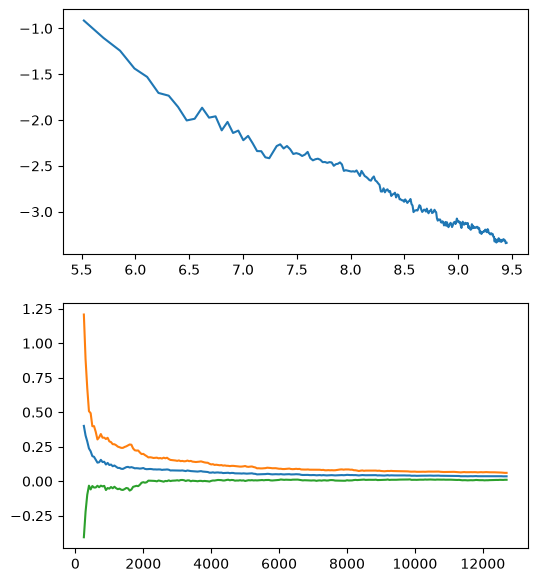

In [260]:
median_mse = np.median(mse_mc, axis=1)
std_mse = np.std(mse_mc, axis=1)

fig, axes = plt.subplots(2, 1, figsize=(6, 7))

axes[0].plot(np.log(np.arange(startup_n + 50, startup_n + 50 * (epochs + 1), 50)), np.log(median_mse))

axes[1].plot(np.arange(startup_n + 50, startup_n + 50 * (epochs + 1), 50), median_mse)
axes[1].plot(np.arange(startup_n + 50, startup_n + 50 * (epochs + 1), 50), median_mse + 2*std_mse)
axes[1].plot(np.arange(startup_n + 50, startup_n + 50 * (epochs + 1), 50), median_mse - 2*std_mse)

plt.show()

In [263]:
import statsmodels.api as sm

sm.OLS(exog=sm.add_constant(np.log(np.arange(startup_n + 50, startup_n + 50 * (epochs + 1), 50))), endog=np.log(median_mse)).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.968
Model:                            OLS   Adj. R-squared:                  0.968
Method:                 Least Squares   F-statistic:                     5944.
Date:                Thu, 16 Jul 2026   Prob (F-statistic):          1.23e-149
Time:                        17:41:47   Log-Likelihood:                 360.14
No. Observations:                 200   AIC:                            -716.3
Df Residuals:                     198   BIC:                            -709.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.5752      0.060     26.228      0.000       1.457       1.694
x1            -0.5213      0.007    -77.095      0.000      -0.535      -0.508
==============================================================================
Omnibus:                        7.067   Durbin-Watson:                   0.321
Prob(Omnibus):                  0.029   Jarque-Bera (JB):                7.345
Skew:                          -0.460   Prob(JB):                       0.0254
Kurtosis:                       2.816   Cond. No.                         190.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [277]:
x_ =np.array([0.99, 0.5, 0.99])
forest.compute_ate(x_) - dgp_mu1(x_)

-0.19584487811636486